In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99
import time

np.random.seed(1111)

In [64]:
kdd = fetch_kddcup99(subset=None, as_frame=True)
df = kdd.data.copy()

df = pd.get_dummies(df, columns=["protocol_type", "service", "flag"], dtype=float)
df = df.astype(float)
df = df.drop(columns=df.columns[df.min() == df.max()])
df = (df-df.min())/(df.max()-df.min())

D = df.to_numpy(dtype=np.float32)
n = D.shape[0]
d = D.shape[1]

print(f"Number of Rows (n) = {n}\nNumber of Columns (d) = {d}")

y = (kdd.target != b'normal.').to_numpy(dtype=float)

Number of Rows (n) = 494021
Number of Columns (d) = 116


In [65]:
#Part a
start = time.perf_counter()
least_sq = np.linalg.lstsq(D, y)
b = least_sq[0]
rank_D = least_sq[2]
end = time.perf_counter()

loss_dyb = np.sum((D@b - y)**2)

time_for_b = end-start
print(f"Loss(D,y,b) = {loss_dyb:.4f}")
print(f"Time taken to find b = {time_for_b:.4f} seconds")

Loss(D,y,b) = 2949.7888
Time taken to find b = 2.9914 seconds


In [66]:
#Part b
print(f"rank(D) = {rank_D}")
m = [50, 100, 200, 500, 1000, 2000, 5000]
trials = {}
for i in m:
    trials[i] = [] #Data will be in form of m:[[trial no., true loss, sketched loss, true loss/loss using b, time to compute S]]

for i in range(0,5):
    for j in range(0,len(m)):
        start = time.perf_counter()

        h = np.random.randint(0, m[j], size=n)
        sigma = np.random.choice([-1, 1], size=n)
        S = np.zeros((m[j], d + 1))
        np.add.at(S, h, sigma[:, None]*np.column_stack([D, y]))
        SD = S[:,:d]
        Sy = S[:,d]

        least_sq_a = np.linalg.lstsq(SD, Sy)
        a = least_sq_a[0]
        end = time.perf_counter()
        loss_dya = np.sum((D@a - y)**2)
        loss_sdsya = np.sum((SD@a-Sy)**2)
        trial_data = [i+1,loss_dya, loss_sdsya, loss_dya/loss_dyb,end-start]
        trials[m[j]].append(trial_data)
        print(f"For trial {i+1} | m = {m[j]} | Loss(D,y,a~) = {trial_data[1]:.4f} | Sketched Loss(SD,Sy,a~) = {trial_data[2]:.4f} | Loss(D,y,a~)/Loss(D,y,b) = {trial_data[3]:.4f}")


rank(D) = 113
For trial 1 | m = 50 | Loss(D,y,a~) = 13653.8275 | Sketched Loss(SD,Sy,a~) = 0.0000 | Loss(D,y,a~)/Loss(D,y,b) = 4.6287
For trial 1 | m = 100 | Loss(D,y,a~) = 126293.1683 | Sketched Loss(SD,Sy,a~) = 0.0000 | Loss(D,y,a~)/Loss(D,y,b) = 42.8143
For trial 1 | m = 200 | Loss(D,y,a~) = 7802.0012 | Sketched Loss(SD,Sy,a~) = 1167.6484 | Loss(D,y,a~)/Loss(D,y,b) = 2.6449
For trial 1 | m = 500 | Loss(D,y,a~) = 3954.5971 | Sketched Loss(SD,Sy,a~) = 2397.6101 | Loss(D,y,a~)/Loss(D,y,b) = 1.3406
For trial 1 | m = 1000 | Loss(D,y,a~) = 3347.7793 | Sketched Loss(SD,Sy,a~) = 2727.0411 | Loss(D,y,a~)/Loss(D,y,b) = 1.1349
For trial 1 | m = 2000 | Loss(D,y,a~) = 3142.5434 | Sketched Loss(SD,Sy,a~) = 2895.5837 | Loss(D,y,a~)/Loss(D,y,b) = 1.0653
For trial 1 | m = 5000 | Loss(D,y,a~) = 3012.0863 | Sketched Loss(SD,Sy,a~) = 2926.5525 | Loss(D,y,a~)/Loss(D,y,b) = 1.0211
For trial 2 | m = 50 | Loss(D,y,a~) = 10857.5856 | Sketched Loss(SD,Sy,a~) = 0.0000 | Loss(D,y,a~)/Loss(D,y,b) = 3.6808
For t

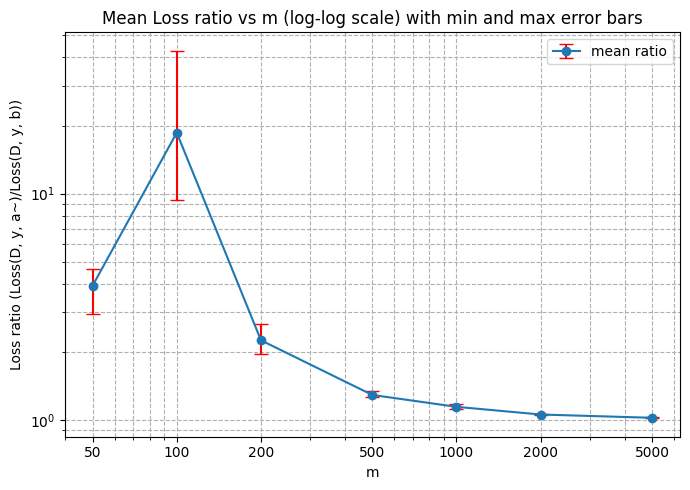

In [67]:
plotting_data = {"means":[],"mins":[],"maxes":[]}

for i in range(0,len(m)):
    ratios = [j[3] for j in trials[m[i]]]
    plotting_data["means"].append(np.mean(ratios))
    plotting_data["mins"].append(np.min(ratios))
    plotting_data["maxes"].append(np.max(ratios))

yerr = np.vstack([np.array(plotting_data['means']) - np.array(plotting_data['mins']), np.array(plotting_data['maxes']) - np.array(plotting_data['means'])])

plt.figure(figsize=(7, 5))
plt.errorbar(m, np.array(plotting_data['means']), yerr=yerr, fmt='o-', capsize=5, ecolor='r', label='mean ratio')
plt.xscale('log')
plt.yscale('log')
plt.xticks(m, [str(int(x)) for x in m])
plt.xlabel('m')
plt.ylabel('Loss ratio (Loss(D, y, a~)/Loss(D, y, b))')
plt.title('Mean Loss ratio vs m (log-log scale) with min and max error bars')
plt.grid(True, which='both', ls='--')
plt.legend()
plt.tight_layout()
plt.show()

In [68]:
#Part c
for i in range(0,len(m)):
    compute_times = [j[4] for j in trials[m[i]]]
    time_for_m = np.mean(compute_times)
    time_ratio = time_for_m/time_for_b
    print(f"For m = {m[i]}\nAverage Time = {time_for_m:.4f} secs | Ratio (Time for m/Time for b) = {time_ratio:.2f}\n")

For m = 50
Average Time = 0.9168 secs | Ratio (Time for m/Time for b) = 0.31

For m = 100
Average Time = 0.8289 secs | Ratio (Time for m/Time for b) = 0.28

For m = 200
Average Time = 0.8422 secs | Ratio (Time for m/Time for b) = 0.28

For m = 500
Average Time = 0.8019 secs | Ratio (Time for m/Time for b) = 0.27

For m = 1000
Average Time = 0.7989 secs | Ratio (Time for m/Time for b) = 0.27

For m = 2000
Average Time = 0.8030 secs | Ratio (Time for m/Time for b) = 0.27

For m = 5000
Average Time = 0.8386 secs | Ratio (Time for m/Time for b) = 0.28



In [69]:
#part d
v = D@b - y
m = [50,500,5000]

ratios = {50:[],500:[],5000:[]}

for i in range(0,100):
    for j in range(0,3):
        h = np.random.randint(0, m[j], size=n)
        sigma = np.random.choice([-1, 1], size=n)
        Sv = np.zeros(m[j])
        np.add.at(Sv, h, sigma*v)
        ratios[m[j]].append(np.sum(Sv**2)/np.sum(v**2))

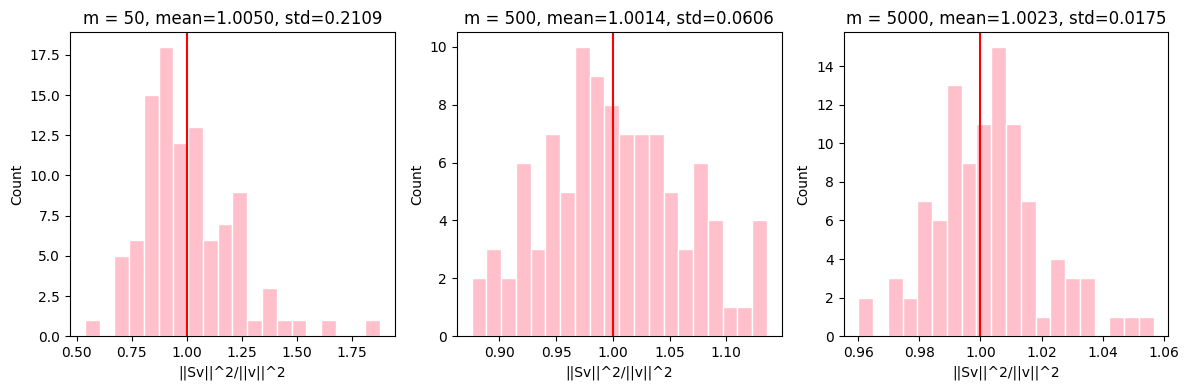

In [70]:
plt.figure(figsize=(12, 4))

for i in range(0,3):
    plt.subplot(1, 3, i+1)
    plt.hist(ratios[m[i]], bins=20, color = 'pink', edgecolor='white')
    plt.axvline(1, color='red', linestyle='-')
    plt.title(f"m = {m[i]}, mean={np.mean(ratios[m[i]]):.4f}, std={np.std(ratios[m[i]]):.4f}")
    plt.xlabel("||Sv||^2/||v||^2")
    plt.ylabel("Count")

plt.tight_layout()
plt.show()

In [71]:
#part e
choice_mask = np.random.choice(n, size=50000, replace=False)
D2 = D[choice_mask]
y2 = y[choice_mask]

least_sq2 = np.linalg.lstsq(D2,y2)
b2 = least_sq2[0]
loss_og = np.sum((D2@b2 - y2)**2)

e_data = {1:[],2:[],3:[],4:[],5:[]}

for i in range(0,5):
    start = time.perf_counter()
    h = np.random.randint(0, 500, size=50000)
    sigma = np.random.choice([-1, 1], size=50000)
    S = np.zeros((500, d+1))
    np.add.at(S, h, sigma[:, None]*np.column_stack([D2, y2]))
    SD = S[:,:d]
    Sy = S[:,d]
    end = time.perf_counter()

    least_sq_a = np.linalg.lstsq(SD, Sy)
    a = least_sq_a[0]
    loss1 = np.sum((D2@a - y2)**2)
    e_data[i+1].extend([end-start,loss1/loss_og])

    start = time.perf_counter()
    S_gauss = np.random.randn(500,50000)
    S_gauss = S_gauss/np.sqrt(500)
    SD2 = S_gauss@D2
    Sy2 = S_gauss@y2
    end = time.perf_counter()

    least_sq_a2 = np.linalg.lstsq(SD2, Sy2)
    a2 = least_sq_a2[0]
    loss2 = np.sum((D2@a2 - y2)**2)

    e_data[i+1].extend([end-start,loss2/loss_og])

plotting_data = np.array(list(e_data.values()))
plotting_means = np.mean(plotting_data,axis=0)

print(f"For CountSketch S\nMean construction time = {np.mean(plotting_means[0]):.4f}s | Mean Loss ratio (Loss(D',y',a~)/Loss(D',y',b'))= {plotting_means[1]:.4f}")
print(f"For Dense Gaussian S\nMean construction time = {np.mean(plotting_means[2]):.4f}s | Mean Loss ratio (Loss(D',y',a~)/Loss(D',y',b'))= {plotting_means[3]:.4f}")


For CountSketch S
Mean construction time = 0.0614s | Mean Loss ratio (Loss(D',y',a~)/Loss(D',y',b'))= 1.3402
For Dense Gaussian S
Mean construction time = 0.4169s | Mean Loss ratio (Loss(D',y',a~)/Loss(D',y',b'))= 1.2665
